# 05 — Preprocessing, step by step, on one conversation

**Stage question.** What exactly happens to a recorded conversation between download and the table of turn pairs, and can each step be checked by eye?

| | |
|---|---|
| **Purpose** | Show every preprocessing step on one real stretch of one interaction, in the order the pipeline applies them. This is a reading surface: it runs no processing of its own beyond re-reading what notebooks 02 and 03 stored, plus one optional re-download that demonstrates the pitch-tracking decision. |
| **Input** | Stored words and voice activity (`data/raw/`), turn and pair tables (`data/processed/`), frame tracks from the audio pass. |
| **Processing** | Words → inter-pausal units → turns and embedded units → pairs; audio → frame level and voice activity → pitch track; turns → voiced-frame count → measurable or dropped. |
| **Output** | `figures/05_preprocessing/` only. |
| **Scientific assumptions** | The rules shown are the preregistered ones. This notebook changes none of them. |
| **Failure modes** | An unrepresentative example. One interaction illustrates the rules; the corpus-wide behaviour is in notebooks 02, 04 and 06. |
| **What to look at** | Whether the turn boundaries fall where the words say they should, whether embedded backchannels sit inside their host turns, and how the per-segment pitch analysis differs from whole-file analysis. |

**Terms.** *Word timing*: start and end of each word, from the upstream aligner. *VAD*: detected speech segments per speaker. *IPU*: inter-pausal unit, a stretch of one speaker's words without a silence of 50 ms or more. *Turn*: a maximal run of one speaker's IPUs with no partner speech between them. *Embedded unit*: a partner IPU lying wholly inside a turn, typically a backchannel. *Pair*: partner turn → reply turn. *F0*: pitch. *Voiced frame*: a 10 ms frame with a pitch estimate.

In [1]:
# Runtime setup — identical in every notebook.
# Colab: mounts Google Drive and uses MyDrive/coda (a copy of the repository) as
#        the project root, then installs the pinned measurement stack.
# Local: uses the repository checkout.
# Every path used below is relative to that root, so Drive and the repository
# have exactly the same layout and outputs can be copied back unchanged.
import os, sys, subprocess
from pathlib import Path

try:
    from google.colab import drive  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    ROOT = Path(os.environ.get('CODA_ROOT', '/content/drive/MyDrive/coda'))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r',
                    str(ROOT / 'requirements-colab.txt')], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

os.environ['CODA_ROOT'] = str(ROOT)
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.runtime import runtime_report
REPORT = runtime_report()

Mounted at /content/drive
runtime        colab   python 3.13.16   cpus 2
memory         12.3 GB free of 13.6 GB
gpu            none (not needed for this stage unless stated)
project disk   11.9 GB free   root = /content/drive/MyDrive/coda
scratch disk   93.4 GB free   (audio lives here briefly)
code           fingerprint e1a10dc2c7145664
artifacts      manifest=True, metadata=True, transcripts=True, turns=True, audio_pass_sessions=293, channel_qc=True


**Runtime check.** The cell above prints free disk on the project root (Drive on Colab) and on the scratch disk where audio briefly lives, memory, CPU count, GPU, the code fingerprint, and which pipeline artifacts already exist. The code fingerprint identifies the exact source and configuration that ran; it is written into every run record and is how a result produced on Drive is matched back to the repository.

In [2]:
# Parameters
STAGE = 'sample'
INTERACTION = None            # an interaction key, or None to pick automatically
WINDOW_S = 40.0               # length of the stretch shown
DEMO_REFETCH = True           # re-download one audio file to show whole-file vs per-segment pitch

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from src.config import FeatureConfig
from src.paths import paths
from src.data.seamless import read_words, read_vad, fetch
from src.data.turns import build_ipus, IPU_GAP_S
from src.features.tracks import Tracks, extract_tracks
from src.features.prosody import turn_file_id
from src.preprocessing.audio_pass import load_tracks
from src.viz import style

P = paths().ensure()
FCFG = FeatureConfig()
style.apply()
FIGDIR = f'05_preprocessing__{STAGE}__{FCFG.pitch_segment_source}'
manifest = pd.read_csv(P.manifest, dtype=str)
turns = pd.read_parquet(P.processed / 'turns.parquet')
pairs = pd.read_parquet(P.processed / 'pairs_candidates.parquet')
qc = pd.read_parquet(P.processed / 'channel_qc.parquet')
usable = qc[qc['failure'].isna()].groupby('interaction_key').size()
usable = usable[usable == 2].index

def busiest_window(starts, width):
    starts = np.sort(np.asarray(starts))
    counts = [((starts >= s0) & (starts < s0 + width)).sum() for s0 in starts]
    return (int(np.max(counts)), float(starts[int(np.argmax(counts))])) if len(starts) else (0, 0.0)

if INTERACTION is None:
    # Deterministic choice: the interaction whose busiest window sits at the 75th percentile
    # of turn density. Busy enough to show turn-taking, not an extreme case.
    cand = turns[turns['interaction_key'].isin(usable) & ~turns['embedded']]
    dens = cand.groupby('interaction_key')['start'].apply(lambda s: busiest_window(s, WINDOW_S)[0])
    dens = dens.sort_values(kind='stable')
    INTERACTION = dens.index[min(int(0.75 * len(dens)), len(dens) - 1)]
ik = INTERACTION
sk = ik.rsplit('_I', 1)[0]
T = turns[turns['interaction_key'] == ik].sort_values('start')
main = T[~T['embedded']]
W0 = float(np.floor(busiest_window(main['start'], WINDOW_S)[1])); W1 = W0 + WINDOW_S
speakers = sorted(T['speaker'].unique())
colour = {s: style.SERIES[i] for i, s in enumerate(speakers)}
print(f"interaction {ik}; window {W0:.0f}–{W1:.0f} s; speakers {speakers}")

interaction V02_S5164_I00000416; window 19–59 s; speakers ['V02_P5148', 'V02_P5200']


## Step 1 → 3: from words to turns

The timeline below stacks the stages for the same 40 seconds. Read it from the top down:

1. **Words**: one tick per timed word, per speaker.
2. **VAD**: the upstream voice-activity segments, per speaker. These are independent of the words.
3. **IPUs**: words joined where the silence between them is under 50 ms.
4. **Turns**: IPUs joined while the partner does not speak in between. Solid bars are turns; hatched bars are embedded units, the partner speech that happened inside someone else's turn.
5. **Pairs**: each arrow runs from a partner turn to the reply that follows it.

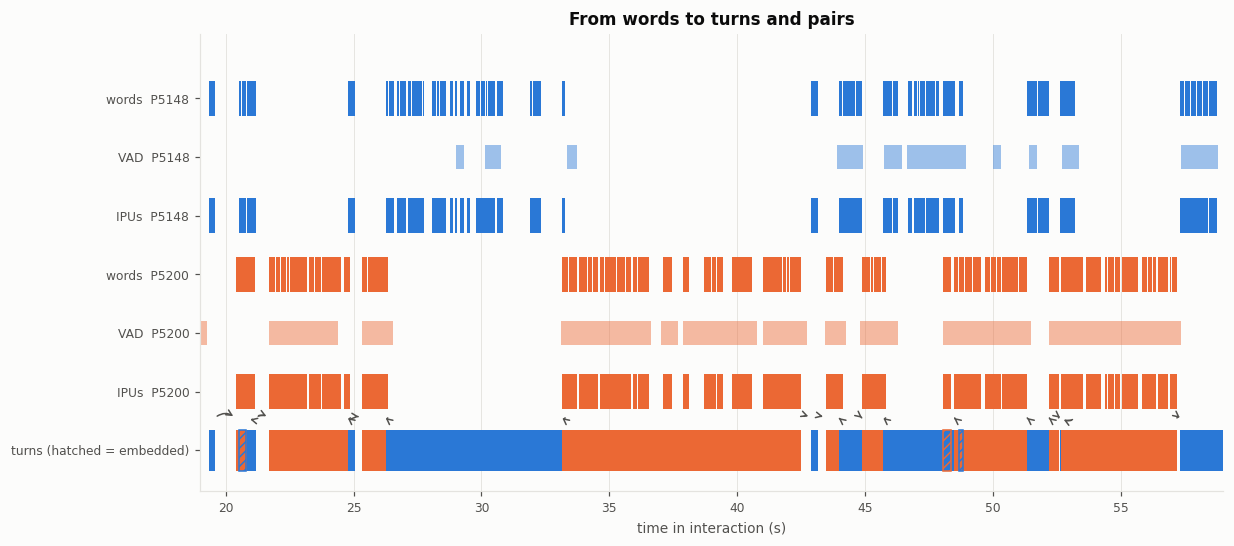

In [4]:
words = {s: read_words(P.raw_transcript / f"{turn_file_id(ik, s)}.jsonl") for s in speakers}
vads = {s: read_vad(P.raw_vad / f"{turn_file_id(ik, s)}.jsonl") for s in speakers}
ipus = {s: build_ipus(words[s]) for s in speakers}

def inwin(df):
    return df[(df['end'] > W0) & (df['start'] < W1)]

lanes = []
for s in speakers:
    lanes += [('words', s), ('VAD', s), ('IPUs', s)]
lanes += [('turns', None)]
ypos = {lane: len(lanes) - i for i, lane in enumerate(lanes)}

fig, ax = plt.subplots(figsize=(12, 5.4))
for s in speakers:
    who = s.rsplit('_P', 1)[1]
    y = ypos[('words', s)]
    for a, b in inwin(words[s])[['start', 'end']].itertuples(index=False):
        ax.add_patch(Rectangle((a, y - 0.3), max(b - a, 0.02), 0.6, color=colour[s], lw=0))
    y = ypos[('VAD', s)]
    for a, b in inwin(vads[s])[['start', 'end']].itertuples(index=False):
        ax.add_patch(Rectangle((a, y - 0.2), b - a, 0.4, color=colour[s], alpha=0.45, lw=0))
    y = ypos[('IPUs', s)]
    for a, b in inwin(ipus[s])[['start', 'end']].itertuples(index=False):
        ax.add_patch(Rectangle((a, y - 0.3), b - a, 0.6, color=colour[s], lw=0))
y = ypos[('turns', None)]
for r in inwin(T).itertuples(index=False):
    ax.add_patch(Rectangle((r.start, y - 0.35), r.end - r.start, 0.7, facecolor=colour[r.speaker] if not r.embedded else 'none',
                           edgecolor=colour[r.speaker], hatch='////' if r.embedded else None, lw=0 if not r.embedded else 1))
P_win = pairs[(pairs['interaction_key'] == ik)].merge(
    main[['turn_id', 'end']].rename(columns={'turn_id': 'partner_turn_id', 'end': 'p_end'}), on='partner_turn_id').merge(
    main[['turn_id', 'start']].rename(columns={'turn_id': 'reply_turn_id', 'start': 'r_start'}), on='reply_turn_id')
P_win = P_win[(P_win['p_end'] > W0) & (P_win['r_start'] < W1)]
for r in P_win.itertuples(index=False):
    ax.annotate('', xy=(r.r_start, y + 0.55), xytext=(r.p_end, y + 0.55),
                arrowprops=dict(arrowstyle='->', color=style.INK_SECONDARY, lw=1,
                                connectionstyle='arc3,rad=-0.4'))
ax.set_xlim(W0, W1)
ax.set_ylim(0.3, len(lanes) + 1.1)
ax.set_yticks([ypos[l] for l in lanes],
              [f"{l[0]}  P{l[1].rsplit('_P', 1)[1]}" if l[1] else 'turns (hatched = embedded)' for l in lanes])
ax.set_xlabel('time in interaction (s)')
ax.set_title('From words to turns and pairs')
ax.grid(axis='y', visible=False)
style.save(fig, P.figures, FIGDIR, 'words_to_turns')
plt.show()

**What is plotted.** The same 40 seconds at each preprocessing stage, one lane per speaker and stage. Colour identifies the speaker in every lane.

**Why it matters.** Every delivery measure is computed over a turn, so a mistake here moves every number downstream. The check is visual. Words should sit inside VAD segments. Each IPU should cover a burst of words. A partner's short utterance falling inside a turn should appear hatched and should not split the turn.

**What would indicate a problem.** Words far outside any VAD segment (a mis-timed transcript). An embedded unit that clearly takes the floor, with the other speaker never resuming. Arrows joining turns of the same speaker (impossible by construction, and asserted in code).

**Conclusion.** Record whether the example matches the rule. The same rule is applied without exception to every interaction.

In [5]:
show = P_win.merge(main[['turn_id', 'duration', 'n_words', 'text']].rename(columns={'turn_id': 'reply_turn_id'}), on='reply_turn_id')
show['text'] = show['text'].str.slice(0, 70)
show[['partner_turn_id', 'reply_turn_id', 'gap_s', 'duration', 'n_words', 'n2_candidates', 'text']].round(2)

,partner_turn_id,reply_turn_id,gap_s,duration,n_words,n2_candidates,text
0,V02_S5164_I00000416_T0001,V02_S5164_I00000416_T0002,0.83,0.76,1,19,"And,"
1,V02_S5164_I00000416_T0002,V02_S5164_I00000416_T0003,-0.30,0.32,1,19,ranch.
2,V02_S5164_I00000416_T0003,V02_S5164_I00000416_T0004,0.52,3.18,9,18,"yeah, that type of lifestyle, like dirt roads,..."
3,V02_S5164_I00000416_T0004,V02_S5164_I00000416_T0005,-0.11,0.30,1,18,Yeah.
4,V02_S5164_I00000416_T0005,V02_S5164_I00000416_T0006,0.24,1.02,2,17,brick houses.
5,V02_S5164_I00000416_T0006,V02_S5164_I00000416_T0007,-0.09,7.02,22,17,"I've been, I've been, my uncle, he, during tha..."
6,V02_S5164_I00000416_T0007,V02_S5164_I00000416_T0008,-0.12,9.34,23,16,"Yeah, yeah, bro, we could walk to the settle f..."
7,V02_S5164_I00000416_T0008,V02_S5164_I00000416_T0009,0.38,0.28,1,16,Yeah.
8,V02_S5164_I00000416_T0009,V02_S5164_I00000416_T0010,0.30,0.66,2,15,"where like,"
9,V02_S5164_I00000416_T0010,V02_S5164_I00000416_T0011,-0.16,0.90,3,16,"It's crazy, huh?"


**The pairs in the window.** `gap_s` is reply start minus partner end; negative means the reply began in overlap. `n2_candidates` counts the partner's other turns at least 10 turns away in this interaction, from which the within-dyad control will draw.

## Step 4 → 5: from audio to frame tracks

The audio pass kept, for every 10 ms frame, the channel's level and, inside the speaker's own voice activity, a pitch estimate. The audio itself is gone; these tracks are what every later measure is computed from.

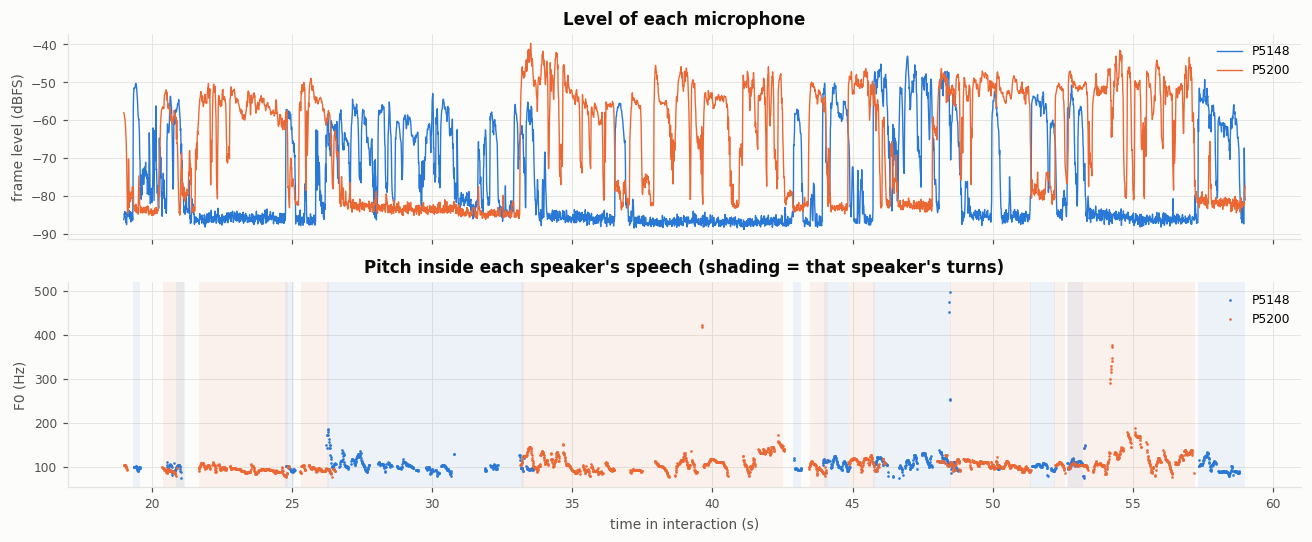

In [6]:
npz = load_tracks(P, sk)
fig, axes = plt.subplots(2, 1, figsize=(12, 5.0), sharex=True)
for s in speakers:
    tr = Tracks.from_npz(npz, turn_file_id(ik, s))
    t = (np.arange(tr.frame_dbfs.size) + 0.5) * tr.step_s
    m = (t >= W0) & (t < W1)
    who = 'P' + s.rsplit('_P', 1)[1]
    axes[0].plot(t[m], tr.frame_dbfs[m], color=colour[s], lw=0.9, label=who)
    tf = tr.f0_t0 + np.arange(tr.f0_hz.size) * tr.step_s
    m = (tf >= W0) & (tf < W1) & (tr.f0_hz > 0)
    axes[1].scatter(tf[m], tr.f0_hz[m], s=3, color=colour[s], label=who)
for r in inwin(main).itertuples(index=False):
    axes[1].axvspan(max(r.start, W0), min(r.end, W1), color=colour[r.speaker], alpha=0.07, lw=0)
axes[0].set_ylabel('frame level (dBFS)'); axes[0].legend(loc='upper right'); axes[0].set_title('Level of each microphone')
axes[1].set_ylabel('F0 (Hz)'); axes[1].set_xlabel('time in interaction (s)')
axes[1].set_title('Pitch inside each speaker\'s speech (shading = that speaker\'s turns)')
axes[1].legend(loc='upper right')
fig.tight_layout()
style.save(fig, P.figures, FIGDIR, 'audio_to_tracks')
plt.show()

**What is plotted.** Top: the 10 ms level of each microphone. Bottom: pitch estimates, drawn over lightly shaded turn spans in the owner's colour.

**Why it matters.** It joins the two halves of preprocessing. Turns come from the words; measurements come from the audio. Pitch points should fall inside the shading of the same speaker's turns, and one microphone's level should rise when its speaker has the turn.

**What would indicate a problem.** Pitch points under the other speaker's shading, which would mean the channel carries the partner's voice. A microphone flat at the floor through its own speaker's turn (gating or a dead channel).

## Step 5 in detail: why pitch is measured per speech segment

Praat, the pitch tracker, treats any stretch quieter than 3% of the loudest point in the analysed sound as silence. This corpus scales every file so its loudest point hits the same peak. A single loud transient, such as a microphone bump or a clipped laugh, then becomes that reference, and ordinary speech falls below 3% of it across the whole file. Analysing each speech segment on its own makes the reference local to the speech being measured and keeps every Praat setting at its default.

With `DEMO_REFETCH = True`, one file is downloaded again, analysed both ways, and deleted. The file chosen is the one with the most flat-topped (clipped) runs in this stage, the case where the difference shows.

file V03_S0265_I00000383_P1510: peak 1.00, flat-top runs 10155
voiced share of detected speech — whole-file analysis: 76.1%; per-segment analysis: 75.8%


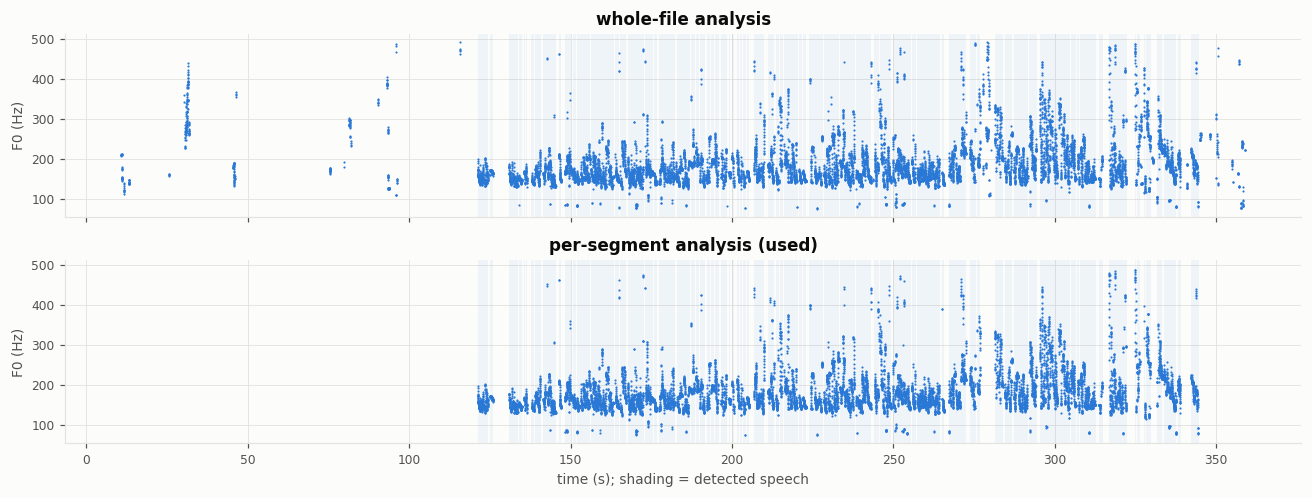

In [7]:
if DEMO_REFETCH:
    stage_files = qc[qc['failure'].isna()].sort_values('flat_top_runs', ascending=False)
    demo = stage_files.iloc[0]
    row = manifest[manifest['file_id'] == demo['file_id']].iloc[0]
    wav = P.audio_scratch / f"{demo['file_id']}.wav"
    import soundfile as sf
    fetch(row['audio_url'], wav)
    x, sr = sf.read(str(wav), dtype='float64')
    vad = read_vad(P.raw_vad / f"{demo['file_id']}.jsonl")
    whole = extract_tracks(x, sr, FCFG)
    local = extract_tracks(x, sr, FCFG, speech_segments=vad[['start', 'end']].to_numpy())
    wav.unlink()                                   # process-and-discard
    n = local.frame_dbfs.size
    speech = np.zeros(n, bool)
    for a, b in vad.itertuples(index=False):
        speech[int(a / 0.01):int(np.ceil(b / 0.01))] = True
    def voiced_in_speech(tr):
        k = np.clip(np.round((np.arange(n) * 0.01 + 0.005 - tr.f0_t0) / 0.01).astype(int), 0, tr.f0_hz.size - 1)
        return float((tr.f0_hz[k][speech] > 0).mean())
    print(f"file {demo['file_id']}: peak {np.abs(x).max():.2f}, flat-top runs {int(demo['flat_top_runs'])}")
    print(f"voiced share of detected speech — whole-file analysis: {voiced_in_speech(whole):.1%}; "
          f"per-segment analysis: {voiced_in_speech(local):.1%}")

    fig, axes = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True, sharey=True)
    for ax, tr, name in [(axes[0], whole, 'whole-file analysis'), (axes[1], local, 'per-segment analysis (used)')]:
        tf = tr.f0_t0 + np.arange(tr.f0_hz.size) * tr.step_s
        m = tr.f0_hz > 0
        ax.scatter(tf[m], tr.f0_hz[m], s=2, color=style.SERIES[0])
        for a, b in vad.itertuples(index=False):
            ax.axvspan(a, b, color=style.SERIES[0], alpha=0.06, lw=0)
        ax.set_title(name); ax.set_ylabel('F0 (Hz)')
    axes[1].set_xlabel('time (s); shading = detected speech')
    fig.tight_layout()
    style.save(fig, P.figures, FIGDIR, 'pitch_whole_vs_segment')
    plt.show()

**What is plotted.** The same file's pitch track computed two ways. Shading marks detected speech.

**Why it matters.** Whole-file analysis can lose most of a speaker's pitch because of one loud event unrelated to speech. That would raise droppage and bias every pitch measure towards the loudest stretches. Per-segment analysis keeps Praat's defaults and measures each stretch of speech on its own terms.

**What would indicate a problem.** Per-segment analysis giving pitch points outside the shading (impossible by construction), or clearly less voicing than whole-file analysis on a clean file.

## Step 6: which turns can carry prosody

A turn needs at least 10 voiced frames (0.1 s of voicing) for its pitch measures to be computed (`configs/features.yaml`). Turns below that are dropped and counted, not imputed.

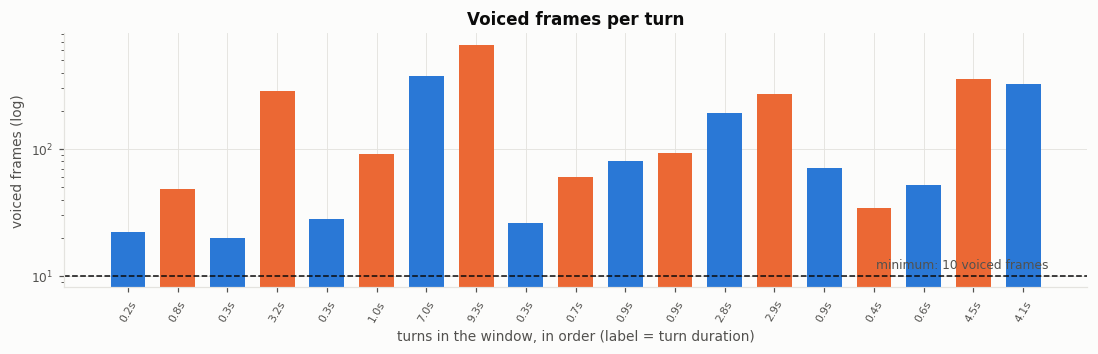

turns in window: 19; below the minimum: 0


In [8]:
vt = []
for r in inwin(main).itertuples(index=False):
    tr = Tracks.from_npz(npz, turn_file_id(ik, r.speaker))
    a = int(np.ceil((r.start - tr.f0_t0) / tr.step_s)); b = int(np.ceil((r.end - tr.f0_t0) / tr.step_s))
    vt.append({'turn_id': r.turn_id, 'speaker': r.speaker, 'duration': r.duration,
               'voiced_frames': int((tr.f0_hz[max(a, 0):max(b, 0)] > 0).sum())})
vt = pd.DataFrame(vt)
fig, ax = plt.subplots(figsize=(12, 3.0))
ax.bar(range(len(vt)), vt['voiced_frames'].clip(lower=0.8), color=[colour[s] for s in vt['speaker']], width=0.7)
ax.axhline(FCFG.min_voiced_frames, color=style.INK, lw=1, linestyle='--')
ax.text(len(vt) - 0.5, FCFG.min_voiced_frames * 1.15, 'minimum: 10 voiced frames', ha='right', fontsize=8,
        color=style.INK_SECONDARY)
ax.set_yscale('log')
ax.set_xticks(range(len(vt)), [f"{d:.1f}s" for d in vt['duration']], rotation=60, fontsize=7)
ax.set_xlabel('turns in the window, in order (label = turn duration)')
ax.set_ylabel('voiced frames (log)')
ax.set_title('Voiced frames per turn')
style.save(fig, P.figures, FIGDIR, 'voiced_frames_per_turn')
plt.show()
print(f"turns in window: {len(vt)}; below the minimum: {(vt['voiced_frames'] < FCFG.min_voiced_frames).sum()}")

**What is plotted.** Voiced frames in each turn of the window, coloured by speaker, on a log scale, with the minimum marked.

**Conclusion.** Turns under the line are short replies with too little voicing to measure pitch. Corpus-wide, the share of such turns is G0's droppage criterion (notebook 04).

## Where each step lives in code

| Step | Module |
|---|---|
| Words, VAD reading | `src/data/seamless.py` (`read_words`, `read_vad`) |
| IPUs, turns, embedded units | `src/data/turns.py` |
| Pairs, N2 availability | `src/data/pairs.py` |
| Audio fetch, checksum, discard | `src/preprocessing/audio_pass.py` |
| Pitch, intensity, frame level | `src/features/tracks.py` |
| Channel quality | `src/preprocessing/channel_qc.py` |
| Voiced frames per turn, droppage | `src/features/prosody.py` |